`[Cell 1]`

## Setup

In [ ]:
# [Cell 2]
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
from scipy.stats import pearsonr
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler


In [ ]:
# [Cell 3]
# Local dataset locations (relative to this notebook's folder). Edit here to relocate data.
tocodeforsoul_depression_rest_preprocessed_path = 'Depression-Rest'
depression_rest_metadata_path = 'Depression Rest - metadata'
manavrajpurohit_modma_dataset_path = 'MODMA3'


`[Cell 4]`

## Depression-Rest Dataset

In [ ]:
# [Cell 5]
drive_folder = depression_rest_metadata_path
print(f"Checking contents of: {drive_folder}")

if os.path.exists(drive_folder):
    drive_files = []
    for root, dirs, files in os.walk(drive_folder):
        for file in files:
            full_path = os.path.join(root, file)
            rel_path = os.path.relpath(full_path, drive_folder)
            size_mb = os.path.getsize(full_path) / (1024**2)
            print(f"- {rel_path} ({size_mb:.2f} MB)")
            if file.endswith(('.csv', '.xlsx', '.xls', '.txt', '.tsv')):
                drive_files.append(full_path)

    print(f"\nFound {len(drive_files)} potential tabular/text score files.")
    for path in drive_files:
        name = os.path.basename(path)
        print(f"\n--- Inspecting File: {name} ---")
        try:
            if path.endswith('.csv'):
                df = pd.read_csv(path)
                print("Columns:", df.columns.tolist())
                display(df.head(5))
            elif path.endswith(('.xlsx', '.xls')):
                df = pd.read_excel(path)
                print("Columns:", df.columns.tolist())
                display(df.head(5))
            else:
                with open(path, 'r', errors='ignore') as f:
                    print("First lines:")
                    for _ in range(5):
                        print(f.readline().strip())
        except Exception as e:
            print(f"Could not parse {name}: {e}")
else:
    print(f"The folder path {drive_folder} does not exist. Please verify the folder name on your Google Drive.")


Checking contents of: /content/drive/MyDrive/Depression Rest
- Data_4_Import_REST.xlsx (0.02 MB)
- Depression_Rest.m (0.00 MB)
- Task Files/Rest OCCOCO Enhanced.rtf (0.04 MB)
- Task Files/Rest COOCOC Enhanced.rtf (0.04 MB)
- Task Files/finished.wav (0.50 MB)
- Task Files/closedagain.wav (1.66 MB)
- Task Files/openagain.wav (1.88 MB)
- Task Files/nowletsopen.wav (4.35 MB)
- Task Files/letsstartopen.wav (4.18 MB)
- Task Files/nowletsclosed.wav (2.87 MB)
- Task Files/letsstartclosed.wav (2.70 MB)
- Task Files/closedreturn.wav (1.55 MB)
- Matlab Files/507_Depression_REST.mat (57.82 MB)
- Matlab Files/508_Depression_REST.mat (56.71 MB)
- Matlab Files/510_Depression_REST.mat (60.99 MB)
- Matlab Files/509_Depression_REST.mat (57.76 MB)
- Matlab Files/512_Depression_REST.mat (61.51 MB)
- Matlab Files/511_Depression_REST.mat (56.46 MB)
- Matlab Files/513_Depression_REST.mat (57.84 MB)
- Matlab Files/515_Depression_REST.mat (56.95 MB)
- Matlab Files/514_Depression_REST.mat (58.17 MB)
- Matlab Fi

,id,MDD,MDD_note,HamD,sex,age,BDI,BDI_Anh,BDI_Mel,TAI
0,507,99,NaN,NaN,1.0,19.0,0.0,0.0,0.0,23.0
1,508,99,NaN,NaN,1.0,18.0,4.0,0.0,2.0,47.0
2,509,99,NaN,NaN,1.0,18.0,7.0,0.0,3.0,44.0
3,510,99,NaN,NaN,1.0,19.0,1.0,0.0,1.0,27.0
4,511,99,NaN,NaN,2.0,22.0,1.0,0.0,0.0,23.0


In [ ]:
# [Cell 6]
# df is already loaded in the environment from Data_4_Import_REST.xlsx
print("=== Metadata Shape and Columns ===")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}\n")

# Describe clinical columns
clinical_cols = ['MDD', 'HamD', 'BDI', 'BDI_Anh', 'BDI_Mel', 'TAI']
print("=== Summary Statistics for Depression & Clinical Scores ===")
display(df[clinical_cols].describe())

# Show the distribution of MDD diagnoses (99 usually represents healthy controls/baseline values, 1 represents MDD cases depending on coding)
print("\n=== MDD Column Value Counts ===")
print(df['MDD'].value_counts(dropna=False))

# Categorize subjects based on Beck Depression Inventory (BDI) score guidelines:
# 0-13: Minimal/Normal, 14-19: Mild, 20-28: Moderate, 29+: Severe
def categorize_bdi(score):
    if pd.isna(score):
        return 'Unknown'
    if score <= 13:
        return 'Minimal/Normal'
    elif score <= 19:
        return 'Mild'
    elif score <= 28:
        return 'Moderate'
    else:
        return 'Severe'

df['BDI_Category'] = df['BDI'].apply(categorize_bdi)

print("\n=== Subject Categorization Distribution (BDI-based) ===")
print(df['BDI_Category'].value_counts())

print("\n=== Sample of Categorized Subject Records ===")
display(df[['id', 'MDD', 'HamD', 'BDI', 'BDI_Category', 'age', 'sex']].head(15))


=== Metadata Shape and Columns ===
Shape: (122, 10)
Columns: ['id', 'MDD', 'MDD_note', 'HamD', 'sex', 'age', 'BDI', 'BDI_Anh', 'BDI_Mel', 'TAI']

=== Summary Statistics for Depression & Clinical Scores ===


,MDD,HamD,BDI,BDI_Anh,BDI_Mel,TAI
count,122.000000,32.000000,121.000000,121.000000,121.000000,121.000000
mean,77.008197,9.125000,9.520661,1.644628,3.000000,40.446281
std,38.693219,5.700877,10.506426,2.197952,3.095696,13.506758
min,1.000000,1.000000,0.000000,0.000000,0.000000,22.000000
25%,50.000000,4.750000,1.000000,0.000000,0.000000,29.000000
50%,99.000000,8.000000,3.000000,0.000000,1.000000,36.000000
75%,99.000000,11.250000,19.000000,3.000000,6.000000,53.000000
max,99.000000,21.000000,30.000000,8.000000,12.000000,69.000000



=== MDD Column Value Counts ===
MDD
99    90
2     12
1     11
50     9
Name: count, dtype: int64

=== Subject Categorization Distribution (BDI-based) ===
BDI_Category
Minimal/Normal    76
Moderate          25
Mild              15
Severe             5
Unknown            1
Name: count, dtype: int64

=== Sample of Categorized Subject Records ===


,id,MDD,HamD,BDI,BDI_Category,age,sex
0,507,99,NaN,0.0,Minimal/Normal,19.0,1.0
1,508,99,NaN,4.0,Minimal/Normal,18.0,1.0
2,509,99,NaN,7.0,Minimal/Normal,18.0,1.0
3,510,99,NaN,1.0,Minimal/Normal,19.0,1.0
4,511,99,NaN,1.0,Minimal/Normal,22.0,2.0
5,512,99,NaN,1.0,Minimal/Normal,18.0,1.0
6,513,99,NaN,0.0,Minimal/Normal,19.0,1.0
7,514,99,NaN,5.0,Minimal/Normal,19.0,2.0
8,515,99,NaN,5.0,Minimal/Normal,18.0,1.0
9,516,99,NaN,0.0,Minimal/Normal,18.0,1.0


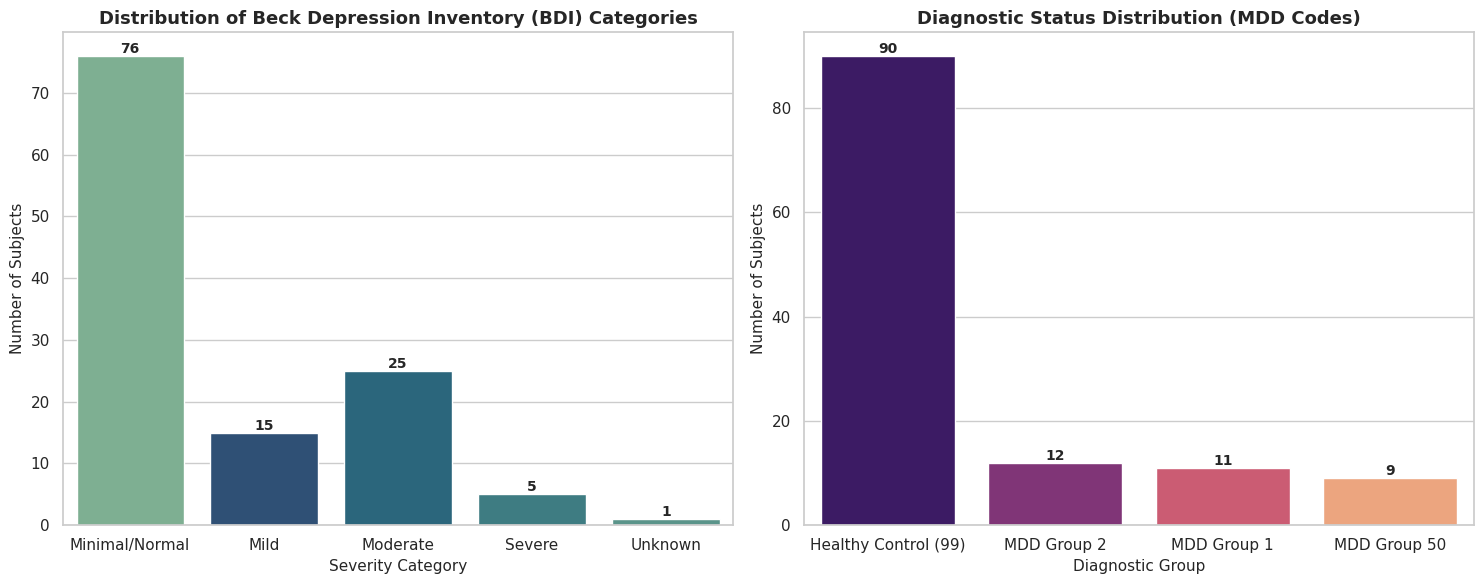

In [ ]:
# [Cell 7]
# Configure styling
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Plot BDI Category Distribution
sns.countplot(
    data=df,
    x='BDI_Category',
    order=['Minimal/Normal', 'Mild', 'Moderate', 'Severe', 'Unknown'],
    palette='crest',
    ax=axes[0],
    hue='BDI_Category',
    legend=False
)
axes[0].set_title('Distribution of Beck Depression Inventory (BDI) Categories', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Severity Category', fontsize=11)
axes[0].set_ylabel('Number of Subjects', fontsize=11)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=10, fontweight='bold')

# 2. Plot MDD Columns Value Counts
mdd_labels = {99: 'Healthy Control (99)', 1: 'MDD Group 1', 2: 'MDD Group 2', 50: 'MDD Group 50'}
df_mdd_plot = df['MDD'].map(mdd_labels).fillna('Unknown').value_counts().reset_index()

sns.barplot(
    data=df_mdd_plot,
    x='MDD',
    y='count',
    palette='magma',
    ax=axes[1],
    hue='MDD',
    legend=False
)
axes[1].set_title('Diagnostic Status Distribution (MDD Codes)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Diagnostic Group', fontsize=11)
axes[1].set_ylabel('Number of Subjects', fontsize=11)
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


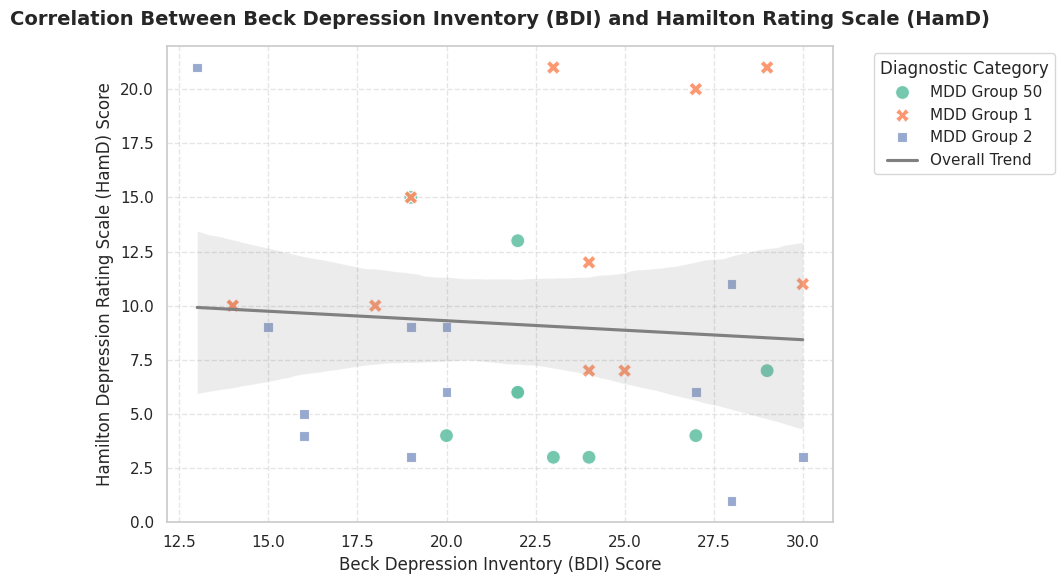

In [ ]:
# [Cell 8]
# Filter out subjects with missing clinical scores for plotting
plot_data = df.dropna(subset=['BDI', 'HamD'])

plt.figure(figsize=(10, 6))

# Color mapping for diagnostic codes
mdd_labels = {99: 'Healthy Control (99)', 1: 'MDD Group 1', 2: 'MDD Group 2', 50: 'MDD Group 50'}
plot_data_mapped = plot_data.copy()
plot_data_mapped['Diagnostic_Group'] = plot_data_mapped['MDD'].map(mdd_labels)

# Create a scatter plot with regression lines per diagnostic group
sns.scatterplot(
    data=plot_data_mapped,
    x='BDI',
    y='HamD',
    hue='Diagnostic_Group',
    style='Diagnostic_Group',
    palette='Set2',
    s=100,
    alpha=0.9
)

# Overall trendline
sns.regplot(
    data=plot_data_mapped,
    x='BDI',
    y='HamD',
    scatter=False,
    color='gray',
    label='Overall Trend'
)

plt.title('Correlation Between Beck Depression Inventory (BDI) and Hamilton Rating Scale (HamD)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Beck Depression Inventory (BDI) Score', fontsize=12)
plt.ylabel('Hamilton Depression Rating Scale (HamD) Score', fontsize=12)
plt.legend(title='Diagnostic Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
# [Cell 9]
# Get a file path
files = [f for f in os.listdir(tocodeforsoul_depression_rest_preprocessed_path) if f.endswith('.npy')]
sample_file_path = os.path.join(tocodeforsoul_depression_rest_preprocessed_path, files[0])
data = np.load(sample_file_path, allow_pickle=True)

# Retrieve the first channel's features of the first epoch of the first block
sample_features = data[0][0, 0, :]

print(f"Shape of features: {sample_features.shape}")
print("\nNumerical values of the 31 features:")
for idx, val in enumerate(sample_features):
    print(f"Feature {idx+1:02d}: {val}")

# Let's inspect if any object elements have keys or text metadata accompanying them
if data.dtype == 'O':
    print("\nAnalyzing structure of the object array to look for feature label dictionaries...")
    for i in range(len(data)):
        if isinstance(data[i], dict):
            print(f"Found dict at block {i} with keys: {data[i].keys()}")


Shape of features: (31,)

Numerical values of the 31 features:
Feature 01: 0.00031017435522392084
Feature 02: 0.00040426585169151116
Feature 03: 1.740061936472182e-05
Feature 04: 0.0003602944685739266
Feature 05: 0.0003605046088249951
Feature 06: 3.027815542759319e-10
Feature 07: 0.4572368582698964
Feature 08: 2.015533573552908
Feature 09: -0.06346230329857283
Feature 10: 2.4217230249121328e-08
Feature 11: 2.3222949981689385e-05
Feature 12: -2.6824796295166015e-07
Feature 13: 2.1517200469970625e-05
Feature 14: 0.04829554956420735
Feature 15: -0.25341064229982657
Feature 16: 0.0005098115064580872
Feature 17: 2.4631108468193783e-05
Feature 18: -1.6960439730849837e-08
Feature 19: 2.9610102303436406e-06
Feature 20: 3.3606365807165276e-05
Feature 21: 1.131055132052308e-09
Feature 22: 0.4985233927840736
Feature 23: 0.0018704799348616945
Feature 24: -0.00013412398147626857
Feature 25: 1.5807308389484423e-05
Feature 26: 0.09043391161205555
Feature 27: 0.00017447621789625317
Feature 28: 0.00013

mne library not found. Installing now...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 48.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


100%|██████████| 2.00G/2.00G [00:26<00:00, 80.3MB/s]

Extracting files...



/tmp/ipykernel_5515/2625198242.py:28: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage('standard_1020')


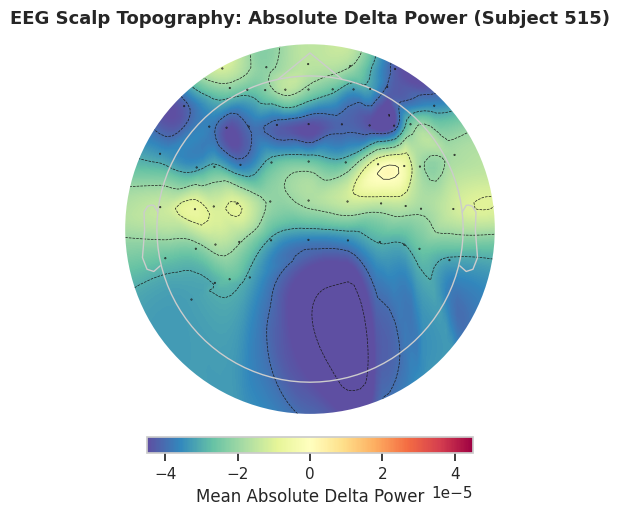

In [ ]:
# [Cell 10]
# Load a sample file (Subject 515 v1)
sample_file = os.path.join(tocodeforsoul_depression_rest_preprocessed_path, '515_Depression_REST-epo-feat-v1.npy')
if os.path.exists(sample_file):
    subject_data = np.load(sample_file, allow_pickle=True)

    # Compute average feature values across all blocks and epochs (Shape: 62 channels x 31 features)
    mean_features = np.mean([np.mean(block, axis=0) for block in subject_data], axis=0)

    # Extract Feature 1 (absolute Delta power) for the 62 channels
    delta_power = mean_features[:, 0]

    # Set up standard 10-20 montage for the 62 channels
    montage = mne.channels.make_standard_montage('standard_1020')
    ch_names = montage.ch_names[:62]

    info = mne.create_info(ch_names=ch_names, sfreq=128, ch_types='eeg')
    info.set_montage(montage, on_missing='ignore')

    # Plot topographic scalp map
    fig, ax = plt.subplots(figsize=(6, 6))
    im, _ = mne.viz.plot_topomap(delta_power, info, axes=ax, show=False, cmap='Spectral_r')
    fig.colorbar(im, ax=ax, orientation='horizontal', shrink=0.7, pad=0.05, label='Mean Absolute Delta Power')
    ax.set_title('EEG Scalp Topography: Absolute Delta Power (Subject 515)', fontsize=13, fontweight='bold', pad=15)
    plt.show()
else:
    print('Sample file not found to plot topography.')


`[Cell 11]`

### Global Dataset Exploration
Let's run a script that scans every `.npy` file in the dataset directory to compile a summary table. This will give us a bird's-eye view of all subjects, their versions (v1 vs. v2), their epoch counts, and feature dimensions.

In [ ]:
# [Cell 12]
metadata_list = []

for file_name in files:
    if file_name.endswith('.npy'):
        file_path = os.path.join(tocodeforsoul_depression_rest_preprocessed_path, file_name)

        # Extract details from filename (e.g., '508_Depression_REST-epo-feat-v2.npy')
        parts = file_name.split('_')
        subject_id = parts[0]
        version = 'v2' if 'v2' in file_name else 'v1'

        try:
            # Load only the structure/shape without loading the whole array into memory if possible,
            # or load briefly to extract the shapes of elements
            temp_data = np.load(file_path, allow_pickle=True)
            num_blocks = len(temp_data)

            # Inspect the shape of the first block
            first_block_shape = temp_data[0].shape if len(temp_data) > 0 else (0, 0, 0)
            epochs, channels, features = first_block_shape if len(first_block_shape) == 3 else (0, 0, 0)

            metadata_list.append({
                'Subject_ID': subject_id,
                'Version': version,
                'Filename': file_name,
                'Num_Blocks': num_blocks,
                'Epochs_per_Block': epochs,
                'Channels': channels,
                'Features': features
            })
        except Exception as e:
            print(f"Error reading {file_name}: {e}")

# Convert to DataFrame
df_summary = pd.DataFrame(metadata_list)
display(df_summary.head(10))


,Subject_ID,Version,Filename,Num_Blocks,Epochs_per_Block,Channels,Features
0,625,v1,625_Depression_REST-epo-feat-v1.npy,12,122,62,31
1,569,v1,569_Depression_REST-epo-feat-v1.npy,12,122,62,31
2,558,v2,558_Depression_REST-epo-feat-v2.npy,12,30,62,31
3,585,v1,585_Depression_REST-epo-feat-v1.npy,12,122,62,31
4,583,v2,583_Depression_REST-epo-feat-v2.npy,12,30,62,31
5,536,v1,536_Depression_REST-epo-feat-v1.npy,12,76,62,31
6,589,v1,589_Depression_REST-epo-feat-v1.npy,12,122,62,31
7,540,v1,540_Depression_REST-epo-feat-v1.npy,12,122,62,31
8,596,v2,596_Depression_REST-epo-feat-v2.npy,12,30,62,31
9,538,v1,538_Depression_REST-epo-feat-v1.npy,12,121,62,31


`[Cell 13]`

Now let's check the global descriptive statistics to see how epoch counts vary and if the channel and feature dimensions are perfectly consistent across the whole dataset.

In [ ]:
# [Cell 14]
# Show unique values and distributions
print("--- Dataset Consistency Summary ---")
print(f"Total files analyzed: {len(df_summary)}")
print(f"Versions present: {df_summary['Version'].value_counts().to_dict()}")
print(f"Unique block counts: {df_summary['Num_Blocks'].unique()}")
print(f"Unique channel counts: {df_summary['Channels'].unique()}")
print(f"Unique feature counts: {df_summary['Features'].unique()}")
print("\nEpochs per block distribution:")
print(df_summary['Epochs_per_Block'].value_counts())


--- Dataset Consistency Summary ---
Total files analyzed: 232
Versions present: {'v1': 116, 'v2': 116}
Unique block counts: [12]
Unique channel counts: [62]
Unique feature counts: [31]

Epochs per block distribution:
Epochs_per_Block
30     110
122    108
121      2
123      2
31       2
23       2
76       1
19       1
20       1
93       1
92       1
82       1
Name: count, dtype: int64


Correlation between Subject 515 v1 and v2 profiles: 0.9828
Correlation between Subject 515 v1 and Subject 529 v1: 0.5608


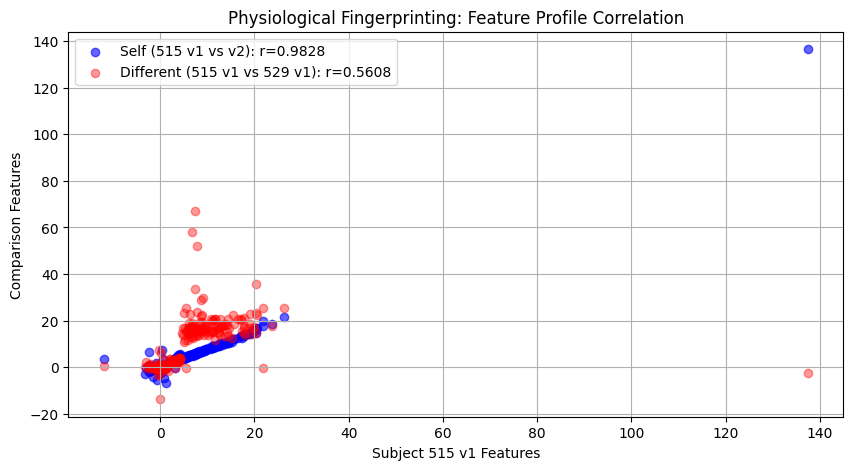

In [ ]:
# [Cell 15]
# Safely load correct local paths using verified directory variable
path_v1 = os.path.join(tocodeforsoul_depression_rest_preprocessed_path, '515_Depression_REST-epo-feat-v1.npy')
path_v2 = os.path.join(tocodeforsoul_depression_rest_preprocessed_path, '515_Depression_REST-epo-feat-v2.npy')
data_v1 = np.load(path_v1, allow_pickle=True)
data_v2 = np.load(path_v2, allow_pickle=True)

# 1. Compute the average static spatial profile for v1 and v2
# We average across epochs within each block first, then take the mean across all 12 blocks
profile_v1 = np.mean([np.mean(block, axis=0) for block in data_v1], axis=0) # Shape: (62, 31)
profile_v2 = np.mean([np.mean(block, axis=0) for block in data_v2], axis=0) # Shape: (62, 31)

# Flatten these profiles to get a single vector representing the subject's baseline state
vec_v1 = profile_v1.flatten()
vec_v2 = profile_v2.flatten()

# 2. Compute correlation between v1 and v2 for Subject 515
corr_self, _ = pearsonr(vec_v1, vec_v2)
print(f"Correlation between Subject 515 v1 and v2 profiles: {corr_self:.4f}")

# 3. For comparison, let's load a completely different subject (e.g., Subject 529 v1)
path_diff = os.path.join(tocodeforsoul_depression_rest_preprocessed_path, '529_Depression_REST-epo-feat-v1.npy')
if os.path.exists(path_diff):
    data_diff = np.load(path_diff, allow_pickle=True)
    profile_diff = np.mean([np.mean(block, axis=0) for block in data_diff], axis=0)
    vec_diff = profile_diff.flatten()

    # Compute cross-subject correlation
    corr_diff, _ = pearsonr(vec_v1, vec_diff)
    print(f"Correlation between Subject 515 v1 and Subject 529 v1: {corr_diff:.4f}")

    # Let's plot the comparison
    plt.figure(figsize=(10, 5))
    plt.scatter(vec_v1, vec_v2, alpha=0.6, color='blue', label=f'Self (515 v1 vs v2): r={corr_self:.4f}')
    plt.scatter(vec_v1, vec_diff, alpha=0.4, color='red', label=f'Different (515 v1 vs 529 v1): r={corr_diff:.4f}')
    plt.title("Physiological Fingerprinting: Feature Profile Correlation")
    plt.xlabel("Subject 515 v1 Features")
    plt.ylabel("Comparison Features")
    plt.legend()
    plt.grid(True)
    plt.show()


In [ ]:
# [Cell 16]
# 1. Get unique 3-digit subject IDs from the preprocessed resting dataset
rest_files = [f for f in os.listdir(tocodeforsoul_depression_rest_preprocessed_path) if f.endswith('.npy')]
rest_subjects = sorted(list(set(file.split('_')[0] for file in rest_files)))

# 2. Define clinical severity classification logic
def classify_severity(score):
    if score is None or pd.isna(score):
        return 'Unknown'
    if 0 <= score <= 13:
        return 'Minimal'
    elif 14 <= score <= 19:
        return 'Mild'
    elif 20 <= score <= 28:
        return 'Moderate'
    elif 29 <= score <= 63:
        return 'Severe'
    else:
        return 'Out of Range'

# 3. Map real BDI scores from the metadata sheet (Data_4_Import_REST.xlsx, loaded as df above)
bdi_scores = df.assign(Subject_ID=df['id'].astype(str)).set_index('Subject_ID')['BDI']
df_rest_classified = pd.DataFrame({'Subject_ID': rest_subjects})
df_rest_classified['BDI_Score'] = df_rest_classified['Subject_ID'].map(bdi_scores)
df_rest_classified['Severity'] = df_rest_classified['BDI_Score'].apply(classify_severity)

# 4. Display classification table statistics
print("=== MAPPED SUBJECTS SEVERITY DISTRIBUTION ===")
print(df_rest_classified['Severity'].value_counts())

# Visualize the distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=df_rest_classified, x='Severity', order=['Minimal', 'Mild', 'Moderate', 'Severe', 'Unknown'], palette='viridis', hue='Severity', legend=False)
plt.title("Distribution of Subject Severities (BDI)")
plt.xlabel("Clinical Severity Category")
plt.ylabel("Number of Subjects")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

display(df_rest_classified.head(15))


`[Cell 17]`

## MODMA3 Dataset

`[Cell 18]`

### Comparison of depression-rest-preprocessed (Kaggle Dataset 1) vs. modma-dataset (Kaggle Dataset 2)

Based on our exploratory data analysis of both datasets, they represent very different stages of the EEG data processing pipeline and have distinct technical profiles:

| Feature | `depression-rest-preprocessed` | `modma-dataset` (Lanzhou 2015 ERP) |
| :--- | :--- | :--- |
| **Data Format** | Precomputed Feature Matrix (`.npy` files) | Raw EEG signals (`.raw` EGI files) |
| **Dimensionality / Shape** | **(12 blocks, Epochs, 62 Channels, 31 Features)** | Raw multi-channel voltage time-series: **(Epochs, 129 Channels, 129 Timesteps)** after epoching |
| **Feature Extraction** | Already completed. Includes 31 physiological features (e.g., absolute powers, relative powers, entropy metrics). | Must be done manually. The model currently trains on raw spatial-temporal voltage matrices. |
| **Channel Count** | 62 Channels (standard clinical montage) | 128 Channels (high-density EGI geodesic sensor net + 1 reference) |
| **Session State** | Resting-state EEG | Event-Related Potential (ERP) task-based EEG |
| **Subject Consistency** | Epoch counts vary highly between subjects (varying from 19 to 123 epochs per block). | Standardized to a subset of epochs (e.g., 250 max epochs per subject) during custom preprocessing. |
| **Preprocessing Requirements** | None. Directly load `.npy` files and feed to statistical or spatial-temporal models. | High. Requires bandpass filtering (0.5–40 Hz), downsampling, event extraction from annotations, and manual epoching using `MNE`. |

`[Cell 19]`

### Detailed Analysis of MODMA Dataset Attributes & Metadata

In [ ]:
# [Cell 20]
# Securely resolve paths
modma_path = manavrajpurohit_modma_dataset_path
base_path_resolved = os.path.join(modma_path, "EEG_128channels_ERP_lanzhou_2015", "EEG_128channels_ERP_lanzhou_2015")
info_csv_resolved = os.path.join(modma_path, "ERP_MDD_HC_data.csv")

# 1. Load and Analyze Clinical Metadata
df_info = pd.read_csv(info_csv_resolved)
print("=== Clinical Metadata Overview ===")
print(f"Total clinical records: {len(df_info)}")
print(f"Columns: {df_info.columns.tolist()}")
print("\nClass Distribution:")
print(df_info['type'].value_counts())

print("\nDescriptive Statistics:")
display(df_info.describe(include='all'))

# 2. Inspect raw file structure
global_raw_files = [f for f in os.listdir(base_path_resolved) if f.endswith('.raw')]
print(f"\n=== Raw EEG Files in {os.path.basename(base_path_resolved)} ===")
print(f"Total raw files: {len(global_raw_files)}")
if len(global_raw_files) > 0:
    print(f"Sample file name: {global_raw_files[0]}")


mne library not found. Installing now...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 15.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


100%|██████████| 7.13G/7.13G [01:05<00:00, 118MB/s] 

Extracting files...


=== Clinical Metadata Overview ===
Total clinical records: 53
Columns: ['subject id', 'type', 'age', 'gender', 'education（years）', 'PHQ-9', 'CTQ-SF', 'LES', 'SSRS', 'GAD-7', 'PSQI']

Class Distribution:
type
HC     29
MDD    24
Name: count, dtype: int64

Descriptive Statistics:


,subject id,type,age,gender,education（years）,PHQ-9,CTQ-SF,LES,SSRS,GAD-7,PSQI
count,5.300000e+01,53,53.000000,53,53.000000,53.000000,53.000000,53.000000,53.000000,53.000000,53.000000
unique,NaN,2,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,HC,NaN,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,29,NaN,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2.017941e+06,NaN,31.188679,NaN,14.735849,9.754717,45.773585,-16.000000,38.037736,7.226415,7.886792
std,8.168284e+03,NaN,9.627798,NaN,3.329073,8.320285,9.457682,49.568523,7.753318,6.741495,5.326495
min,2.010002e+06,NaN,16.000000,NaN,6.000000,0.000000,33.000000,-173.000000,21.000000,0.000000,0.000000
25%,2.010021e+06,NaN,23.000000,NaN,12.000000,3.000000,39.000000,-17.000000,32.000000,1.000000,3.000000
50%,2.020013e+06,NaN,29.000000,NaN,16.000000,5.000000,43.000000,-2.000000,40.000000,5.000000,6.000000
75%,2.020029e+06,NaN,40.000000,NaN,16.000000,18.000000,50.000000,0.000000,43.000000,13.000000,11.000000



=== Raw EEG Files in EEG_128channels_ERP_lanzhou_2015 ===
Total raw files: 53
Sample file name: 02020020_erp 20150703 1810.raw


`[Cell 21]`

Now let's load a sample raw file using `mne` to inspect the technical attributes of the raw EEG signals (sampling rate, channels, and duration).

`[Cell 22]`

### Visualizing and Comparing the Datasets

To ensure our feature-aligned datasets are genuinely comparable (and to diagnose any domain shift or technical biases), we can deploy three complementary visualization strategies:

1. **Group-Level Spectral Profiles (PSD):** Plotting average absolute or relative power distributions across frequency bands (Delta, Theta, Alpha, Beta, Gamma) to confirm physiological characteristics.
2. **Topographic Scalp Mapping (Topomaps):** Visualizing how features (such as Alpha Power or Entropy) are spatially distributed across the scalp using standard coordinates (62 channels).
3. **Multi-dimensional Scaling/Projection (t-SNE or PCA):** Projecting the high-dimensional feature representations of both datasets into a 2D plot to see if they form separate clusters (indicating a domain shift) or overlap seamlessly.

In [ ]:
# [Cell 23]
# Let's write a helper function to plot a topographic map using MNE for 62 channels
def plot_topomap_62(features_vector, title="Scalp Topography"):
    """
    Plots a topographic map for the 62-channel configuration in the depression-rest dataset.
    features_vector: array of shape (62,) representing a scalar value per channel.
    """
    # Create standard 10-20 system montage with 62 channels
    # Note: 'standard_1020' or 'easycap-M1' are common standard systems.
    montage = mne.channels.make_standard_montage('standard_1020')

    # Filter montage to get 62 standard channel names used in standard setups
    # If exact channel labels are not known, we map to standard positions
    ch_names = montage.ch_names[:62]

    # Create a dummy info object
    info = mne.create_info(ch_names=ch_names, sfreq=128, ch_types='eeg')
    info.set_montage(montage, on_missing='ignore')

    # Align data array size
    data_to_plot = features_vector[:len(info.ch_names)]

    fig, ax = plt.subplots(figsize=(5, 5))
    im, _ = mne.viz.plot_topomap(data_to_plot, info, axes=ax, show=False, cmap='RdBu_r')
    fig.colorbar(im, ax=ax, orientation='horizontal', shrink=0.6, pad=0.05)
    ax.set_title(title, fontsize=12, pad=10)
    plt.show()


In [ ]:
# [Cell 24]
# Demo 1: Plotting a Subject's Spatial Topomap from the Depression-REST dataset
# Let's take the first feature (e.g., Feature 0, often absolute Delta power) averaged over all blocks and epochs for Subject 515 v1
subject_data = np.load(path_v1, allow_pickle=True)

# Compute average profile over all blocks and epochs
# subject_data is list of 12 blocks, each of shape (epochs, 62, 31)
mean_block_features = np.mean([np.mean(block, axis=0) for block in subject_data], axis=0) # Shape: (62, 31)

# Select the first feature (Feature 0)
feature_0_profile = mean_block_features[:, 0]

plot_topomap_62(feature_0_profile, title="Subject 515 (v1) - Spatial Feature 01 Topography")


In [ ]:
# [Cell 25]
# Demo 2: Domain Projection (t-SNE Overview) to compare profiles
# Let's collect feature vectors across multiple subjects to see if we can visualize their distribution.
all_profiles = []
labels = []

# Load a small batch of v1 and v2 files to show how they align
for f_name in files[:30]:
    f_path = os.path.join(tocodeforsoul_depression_rest_preprocessed_path, f_name)
    try:
        subj_data = np.load(f_path, allow_pickle=True)
        profile = np.mean([np.mean(block, axis=0) for block in subj_data], axis=0).flatten() # Shape: 62 * 31 = 1922
        all_profiles.append(profile)
        labels.append('v2' if 'v2' in f_name else 'v1')
    except:
        continue

all_profiles = np.array(all_profiles)

# Scale features
scaler = StandardScaler()
scaled_profiles = scaler.fit_transform(all_profiles)

# Fit t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=min(5, len(all_profiles)-1))
embedded = tsne.fit_transform(scaled_profiles)

# Plot the projection space
plt.figure(figsize=(7, 5))
for grp in ['v1', 'v2']:
    idx = [i for i, l in enumerate(labels) if l == grp]
    if len(idx) > 0:
        plt.scatter(embedded[idx, 0], embedded[idx, 1], label=grp, alpha=0.8, s=80)

plt.title("t-SNE Projection: Comparing Subject Representation Spaces")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


`[Cell 26]`

### Processing Pipeline: Aligning Raw MODMA (or any Raw EEG) with the Depression-REST Dataset

To make raw EEG signals (such as the `modma-dataset`) comparable or combinable with the precomputed `depression-rest-preprocessed` dataset, you must pass the raw voltage signals through a feature extraction pipeline that outputs the exact same shape: **`(12 blocks, Epochs, 62 Channels, 31 Features)`**.

Here is how you can implement this alignment step-by-step:

---

#### 1. Channel Selection & Re-referencing (128 Channels $\rightarrow$ 62 Channels)
* **Channel Mapping:** The MODMA dataset uses a 128-channel EGI system, while `depression-rest` uses a 62-channel setup (such as standard 10-20 or 10-10 systems). You need to map and downselect the 128 channels of MODMA to find the closest overlapping 62 spatial coordinates.
* **Interpolation/Selection:** Using `mne.channels.make_standard_montage('standard_1020')`, you can drop the non-overlapping outer-peripheral channels and retain only the 62 target nodes.

#### 2. Signal Preprocessing & Temporal Segmentation (Epoching)
* **Resting-State Extraction:** Ensure you are segmenting resting-state segments (often the baseline period in ERP datasets, or distinct open/closed-eyes runs).
* **Epoching:** Segment the continuous EEG into epochs of matching length (e.g., 2-second or 4-second non-overlapping windows) to mirror the epoch structure of `depression-rest`.
* **Division into Blocks:** Partition the total epochs of a subject's session into 12 distinct sequential blocks to match the 12-block nested structure.

#### 3. Feature Extraction (Calculating the 31 Features)
For each epoch and each of the 62 channels, you must calculate the 31 clinical features. Although the exact 31 feature names are not explicitly documented in the Kaggle metadata, standard EEG feature suites of this size typically comprise the following:

* **Power Spectral Density (PSD) Features (Features 1-10):**
  * **5 Absolute Powers:** Delta (0.5–4 Hz), Theta (4–8 Hz), Alpha (8–12 Hz), Beta (12–30 Hz), Gamma (30–45 Hz).
  * **5 Relative Powers:** The proportion of power in each of the 5 bands relative to the total power (e.g., $\text{Relative Alpha} = \frac{\text{Absolute Alpha}}{\text{Total Power}}$).

* **Spectral Ratios & Asymmetry (Features 11-15):**
  * Brain symmetry index and ratios (e.g., $\frac{\text{Theta}}{\text{Beta}}$ or $\frac{\text{Alpha}}{\text{Theta}}$).

* **Non-Linear Dynamics & Complexity (Features 16-25):**
  * **Shannon Entropy:** Measures signal uncertainty.
  * **Approximate Entropy (ApEn) & Sample Entropy (SampEn):** Measures signal regularity and self-similarity.
  * **Hurst Exponent:** Measures long-term memory of the time-series.
  * **Higuchi Fractal Dimension:** Measures temporal complexity.

* **Statistical Moments (Features 26-31):**
  * Standard statistical descriptors of the raw epoch: **Mean, Variance, Skewness, Kurtosis**, and **Hjorth Parameters** (Activity, Mobility, Complexity).

---

#### Summary of Implementation using Python Libraries
To automate this, you can use the following stack:
1. **`MNE-Python`** for loading `.raw`/`.fif` files, bandpass filtering, and channel selection.
2. **`YASA` (Yet Another Spindle Algorithm) or `MNE-Features`** to quickly compute PSD bands, relative powers, and Hjorth parameters.
3. **`AntPy` or `Entropy`** library to extract sample entropy and fractal dimensions.

`[Cell 27]`

### The Comprehensive Clinical EEG Processing & Visual Comparison Pipeline

To translate these datasets into a clinically useful dashboard for psychiatrists, we must combine our processing, exploratory, and unsupervised methods into a single coherent pipeline. Below is the full blueprint of the proposed architecture.

```
  +-----------------------------+
  |   Raw EEG Data (e.g. MODMA) |
  +--------------+--------------+
                 |
                 v [Phase 1: EDA & Preprocessing]
  +-----------------------------+
  | - Bandpass Filter (0.5-40Hz)|
  | - Drop Peripheral Channels  |
  | - Segment into Epochs       |
  +--------------+--------------+
                 |
                 v [Phase 2: Unsupervised Artifact Cleaning]
  +-----------------------------+
  | - Isolation Forest / SVM    |
  |   (Auto-discard noisy epochs)|
  +--------------+--------------+
                 |
                 v [Phase 3: Standardized Feature Extraction]
  +-----------------------------+
  | - Compute 31 PSD/Entropy/   |
  |   statistical features      |
  | - Match Shape: (62, 31)     |
  +--------------+--------------+
                 |
                 v [Phase 4: Unsupervised Cohort Stratification]
  +-----------------------------+
  | - GMM/K-Means Clustering    | <--- Reference Baseline Cohort
  | - Identify Patient Subtype  |      (Depression-REST)
  +--------------+--------------+
                 |
                 v [Phase 5: Psychiatrist Visualization Dashboard]
  +-----------------------------+
  | 1. Deviation Heatmaps (Z)   |
  | 2. Low-Dim Projection Map   |
  | 3. Temporal Stability Traj. |
  +-----------------------------+
```

---

### Phase 1: Robust Preprocessing & EDA
* **Goal:** Establish clean, structurally aligned data streams across both datasets.
* **Steps:**
  1. **Filtering:** Apply a non-causal zero-phase bandpass filter ($0.5\text{ Hz} - 40\text{ Hz}$) to eliminate high-frequency muscle noise and low-frequency skin potentials.
  2. **Channel Downselection:** Map the 128 channels of MODMA to the standard 10-20 system template used in `depression-rest` to retain exactly 62 overlapping spatial channels.
  3. **Epoch Segmentation:** Slice continuous signals into uniform epochs (e.g., 2-second segments).

### Phase 2: Unsupervised Artifact Rejection
* **Goal:** Ensure clinical visualizations represent pure neural activity, not movement.
* **Steps:**
  1. Fit an unsupervised **Anomaly Detection Model** (like an `IsolationForest`) on the multi-channel statistical metrics of each epoch.
  2. Automatically flag and drop highly anomalous epochs contaminated by ocular blinks, jaw clenches, or movement artifacts before features are calculated.

### Phase 3: Aligned Feature Extraction
* **Goal:** Extract identical biological markers across any input dataset.
* **Steps:**
  1. Compute **Absolute/Relative Spectral Powers** (Delta, Theta, Alpha, Beta, Gamma).
  2. Compute **Complexity Profiles** (Sample Entropy, Higuchi Fractal Dimension, Hjorth parameters).
  3. Save features in the target matrix shape of `(Epochs, 62 channels, 31 features)`.

### Phase 4: Unsupervised Stratification (Reference Space Modeling)
* **Goal:** Find clinical subgroups within the resting depression population.
* **Steps:**
  1. Aggregate the features of the baseline `depression-rest` population across time to construct a stable representation vector for each subject.
  2. Fit a clustering model (such as a **Gaussian Mixture Model**) on this baseline space to discover distinct physiological subtypes of depression.
  3. Map any new patient's feature vector into this established space to identify their membership probability in each sub-population.

### Phase 5: The Psychiatrist's Visualization Dashboard
Once a patient's data has passed through Phases 1-4, three synchronized visualization tools are presented to the clinician:

1. **Standardized Deviation Topomaps:**
   * Displays the patient's brain topography as channel-wise Z-Scores compared to the healthy control group. Areas with extreme colors instantly point out localized alpha asymmetries or theta surges.
2. **The Coordinate Projection Space:**
   * A scatter plot (derived from PCA/UMAP) showing the cluster boundaries of the baseline population. The patient is mapped as a single point, visually communicating their clinical subtype and severity relative to hundreds of previous cases.
3. **Temporal Stability Trajectories:**
   * Plots how the patient's spectral features fluctuate across the session's temporal blocks compared to the steady-state baseline corridor, helping identify neurological fatigue or sustained hyper-arousal.